# Module 4: 4-Bit Adder in Qiskit

**Abert Kabore**  
PhD student in Advanced and Equitable Computing

The one-bit and two-bit circuits below are from the supplied notebook,
`QC_Ekert_FA1bit_and_2bit_examp.ipynb`. The four-bit section extends the same
SUM, CARRY, and reverse-CARRY design and tests five pairs of four-bit inputs.


In [1]:
from qiskit import QuantumCircuit
from qiskit_aer.primitives import SamplerV2
from qiskit.visualization import plot_histogram

In [2]:
# Define functions for the ripple carry adder.
def sum(circ, cin, a, b):
    circ.cx(a,b)
    circ.cx(cin,b)

def carry(circ, cin, a, b, cout):
    circ.ccx(a, b, cout)
    circ.cx(a, b)
    circ.ccx(cin, b, cout)

def carry_rev(circ, cin, a, b, cout):
    circ.ccx(cin, b, cout)
    circ.cx(a, b)
    circ.ccx(a, b, cout)


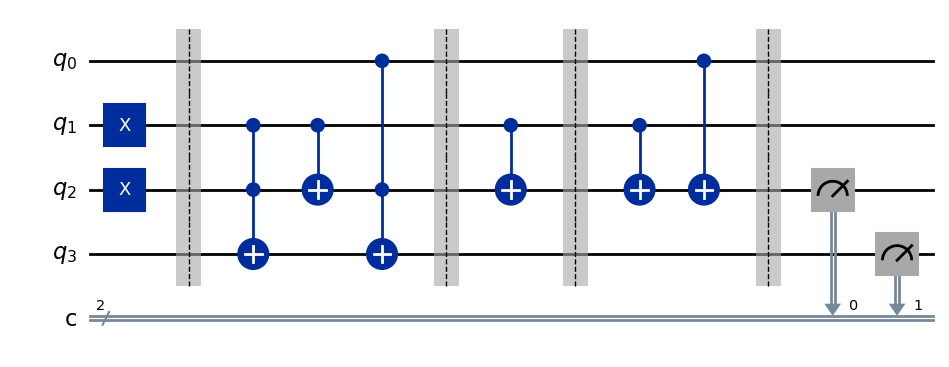

In [3]:
#quantum sum of 3 bits (1-bit FA)
qc = QuantumCircuit(4,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,0]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(1,2)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(3,1) # extract Cout value

qc.draw(output="mpl")

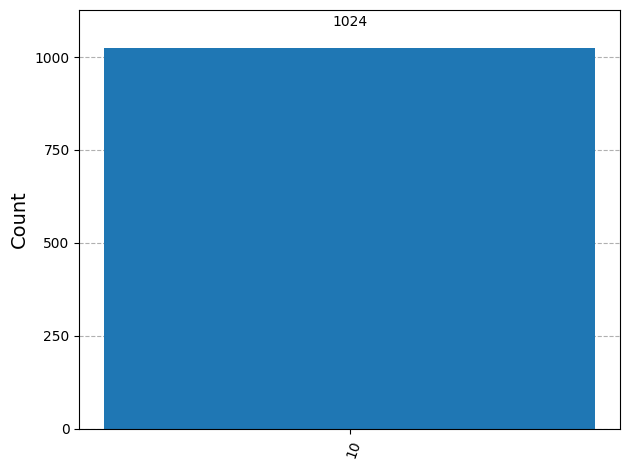

In [4]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- The output 10 occurred in 1,024 of 1,024 shots. Its decimal value, 2, matches 1 + 1 + 0.
- The first bit is the carry-out and the second is the sum bit. Their measured values are 1 and 0, respectively.


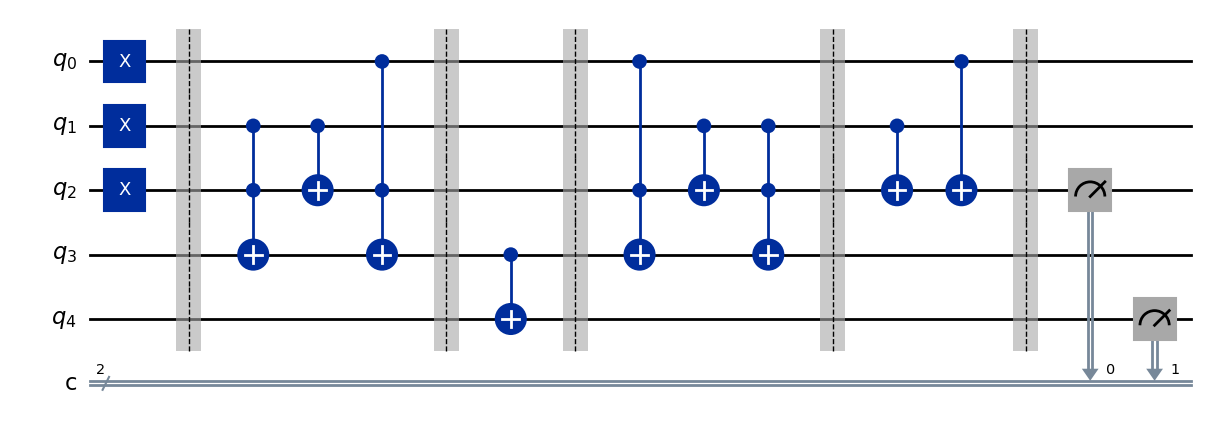

In [5]:
#quantum sum of 3 bits (1-bit FA)
#Another way with 5-bits
#(anticipating a design for an n-bit FA)
qc = QuantumCircuit(5,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,1]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(3,4)
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(4,1) # extract Cout value

qc.draw(output="mpl")


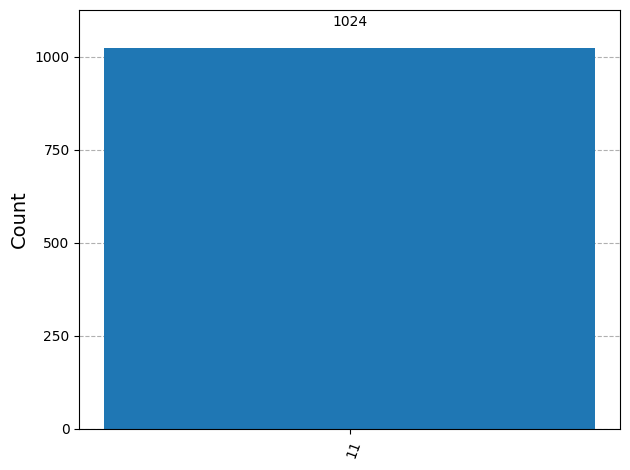

In [6]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- The output 11 occurred in 1,024 of 1,024 shots, matching 1 + 1 + 1 = 3.
- The sum bit and carry-out are both 1. In this five-qubit circuit, the carry-out is copied before reverse-CARRY is applied.


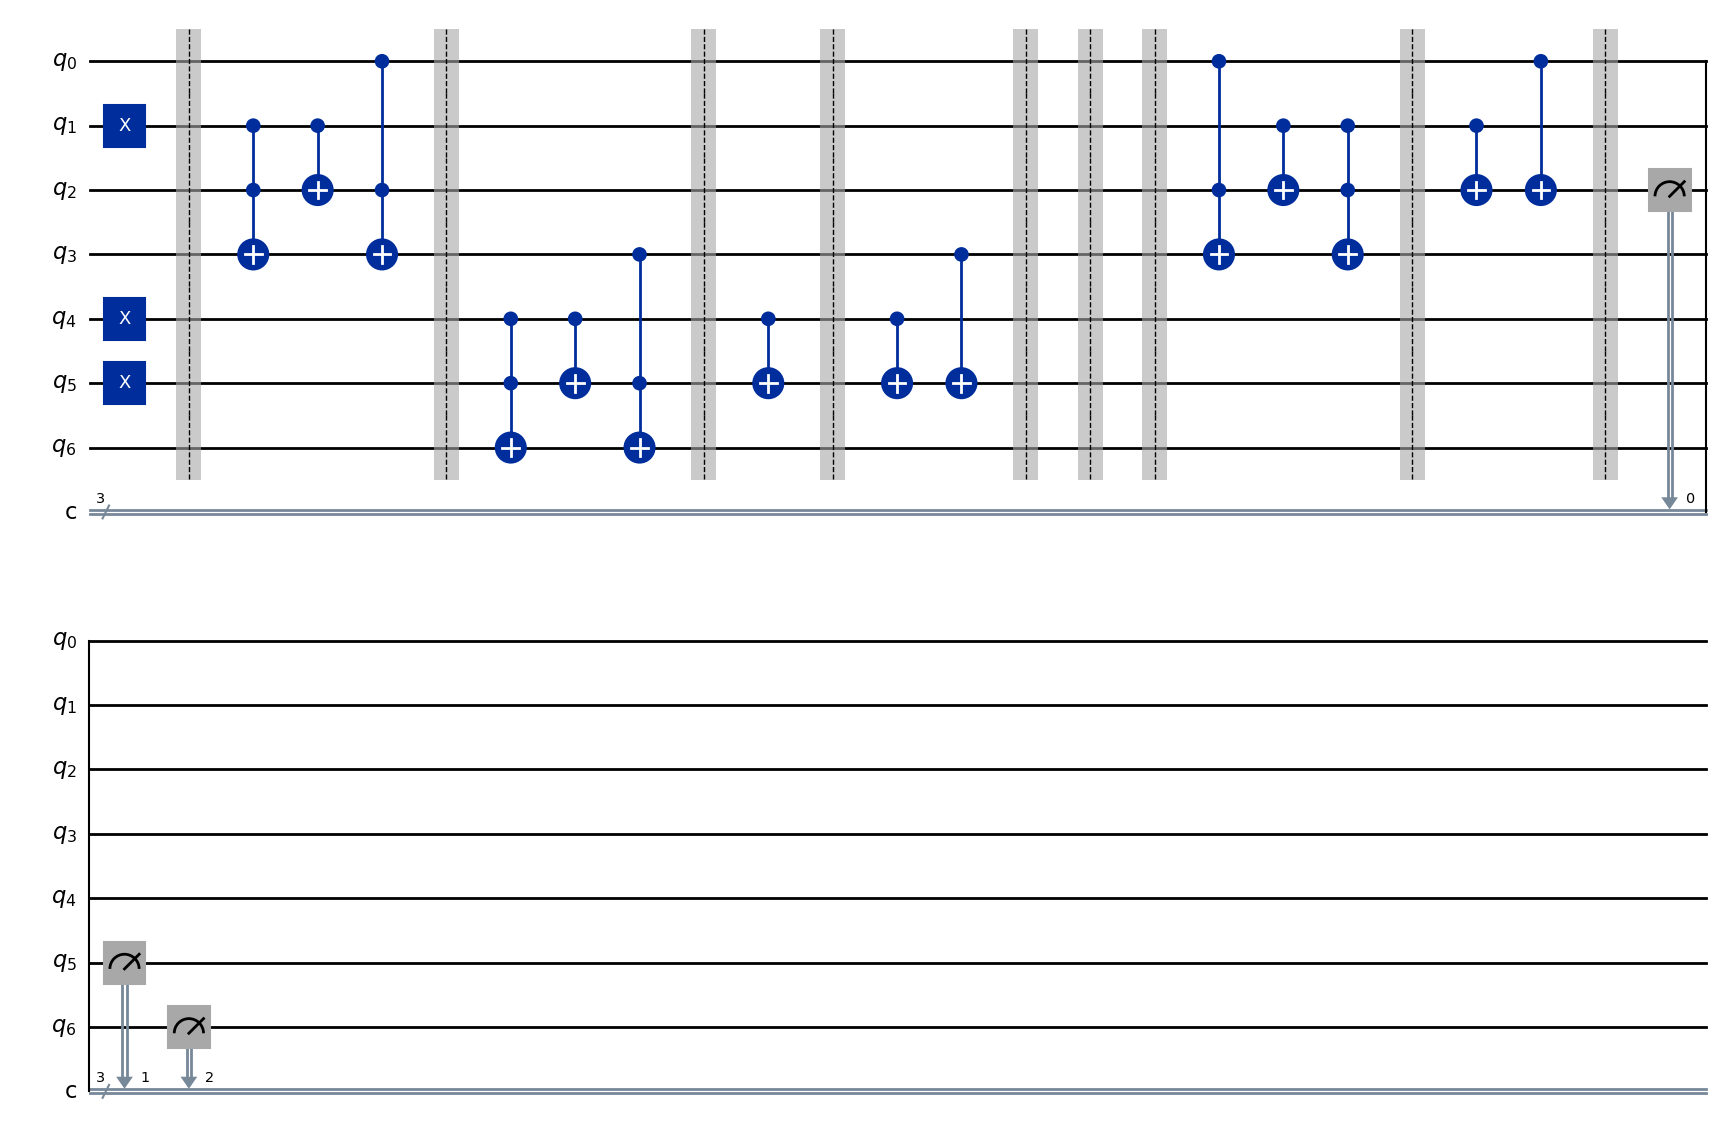

In [7]:
#2-bit FA
qc = QuantumCircuit(7,3)

#Qubits:  0    1    2   3              4   5     6
#Input:  cin0  a0  b0  cin1(=cout0)   a1   b1   cin2(=cout1)

#Qubits:    0    1    2            3     4    5             6
#Output:   cin0  a0  a0+b0+cin0   |0>   a1   a1+b1+cin1   cin2(=cout1)

#use the X gates to toggle the input qubit values
a = [1,1]
b = [1,0]
if a[1] == 1:
  qc.x(1)
if a[0] == 1:
  qc.x(4)

if b[1] == 1:
  qc.x(2)
if b[0] == 1:
  qc.x(5)

qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

carry(qc, 3,4,5,6)
qc.barrier()

qc.cx(4,5)
qc.barrier()
sum(qc, 3,4,5)
qc.barrier()
qc.barrier()
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum_0
qc.measure(5,1) # extract Sum_1
qc.measure(6,2) # extract Sum_2

qc.draw(output="mpl")

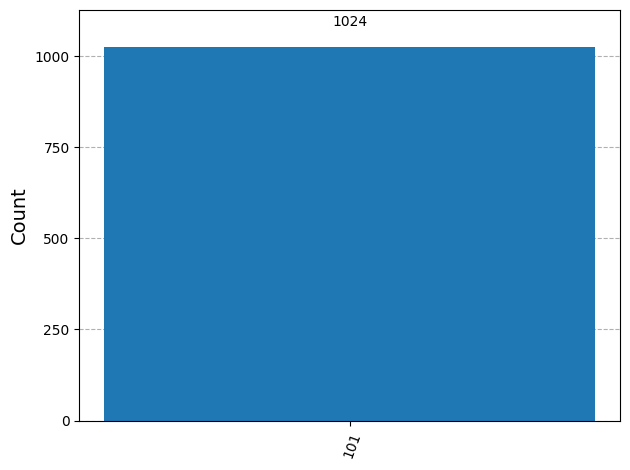

In [8]:
results = SamplerV2(seed=4).run([qc], shots=1024).result()
statistics = results[0].data.c.get_counts()
plot_histogram(statistics)

### Observations

- The output 101 occurred in 1,024 of 1,024 shots. It represents 5, matching the two-bit operands 11 and 10 (3 + 2).
- The carry-out is 1 and the lower two sum bits are 01. The observed relative frequency at 101 is 1.


# 4-Bit Adder

The four-bit circuit uses the `sum`, `carry`, and `carry_rev` functions from the
supplied notebook. Four CARRY stages replace the two stages in its two-bit
circuit. Reverse-CARRY and SUM then compute the sum bits in reverse order.

The inputs are four-bit integers from 0 to 15. The initial carry is zero.
Five measured bits hold the sum, including the final carry-out. Qiskit displays
the final carry on the left, followed by the four sum bits.


In [9]:
from qiskit import QuantumRegister, ClassicalRegister


def adder_qubits(i):
    """Use the (carry, a, b) layout from the supplied two-bit circuit."""
    return 3 * i, 3 * i + 1, 3 * i + 2


def ripple_carry_adder(a, b):
    """Add two unsigned four-bit integers with initial carry zero."""
    if not (0 <= a < 16 and 0 <= b < 16):
        raise ValueError("a and b must be integers from 0 to 15")

    qr = QuantumRegister(13, "q")
    cr = ClassicalRegister(5, "s")
    qc = QuantumCircuit(qr, cr)

    # Load a_i and b_i into the same layout as the two-bit circuit.
    for i in range(4):
        _, ai, bi = adder_qubits(i)
        if (a >> i) & 1:
            qc.x(ai)
        if (b >> i) & 1:
            qc.x(bi)
    qc.barrier()

    # Compute the four carries.
    for i in range(4):
        ci, ai, bi = adder_qubits(i)
        carry(qc, ci, ai, bi, ci + 3)
    qc.barrier()

    # Compute the most significant sum bit.
    ci, ai, bi = adder_qubits(3)
    qc.cx(ai, bi)
    sum(qc, ci, ai, bi)
    qc.barrier()

    # Reverse each remaining carry and compute its sum bit.
    for i in range(2, -1, -1):
        ci, ai, bi = adder_qubits(i)
        carry_rev(qc, ci, ai, bi, ci + 3)
        sum(qc, ci, ai, bi)
        qc.barrier()

    for i in range(4):
        qc.measure(adder_qubits(i)[2], cr[i])
    qc.measure(12, cr[4])
    return qc


def run_counts(circuits, shots=1024):
    """Return measured counts from the local Qiskit Aer simulator."""
    result = SamplerV2(seed=4).run(circuits, shots=shots).result()
    return [r.data.s.get_counts() for r in result]

## Test Cases

The five tests cover zero inputs, addition without carries, carry propagation,
a final carry-out, and the largest four-bit operands. Each circuit is run on
Qiskit Aer with 1,024 shots. The assertions compare the measured bitstrings
with the expected binary sums.


In [10]:
test_cases = [
    (0b0000, 0b0000),
    (0b0101, 0b0010),
    (0b0111, 0b0001),
    (0b1001, 0b0111),
    (0b1111, 0b1111),
]

circuits = [ripple_carry_adder(a, b) for a, b in test_cases]
all_counts = run_counts(circuits)

for index, ((a, b), counts) in enumerate(zip(test_cases, all_counts), 1):
    expected = f"{a + b:05b}"
    assert counts == {expected: 1024}, counts
    print(
        f"Test {index}: {a:04b} + {b:04b} = {expected}; "
        f"counts = {counts}; PASS"
    )

Test 1: 0000 + 0000 = 00000; counts = {'00000': 1024}; PASS
Test 2: 0101 + 0010 = 00111; counts = {'00111': 1024}; PASS
Test 3: 0111 + 0001 = 01000; counts = {'01000': 1024}; PASS
Test 4: 1001 + 0111 = 10000; counts = {'10000': 1024}; PASS
Test 5: 1111 + 1111 = 11110; counts = {'11110': 1024}; PASS


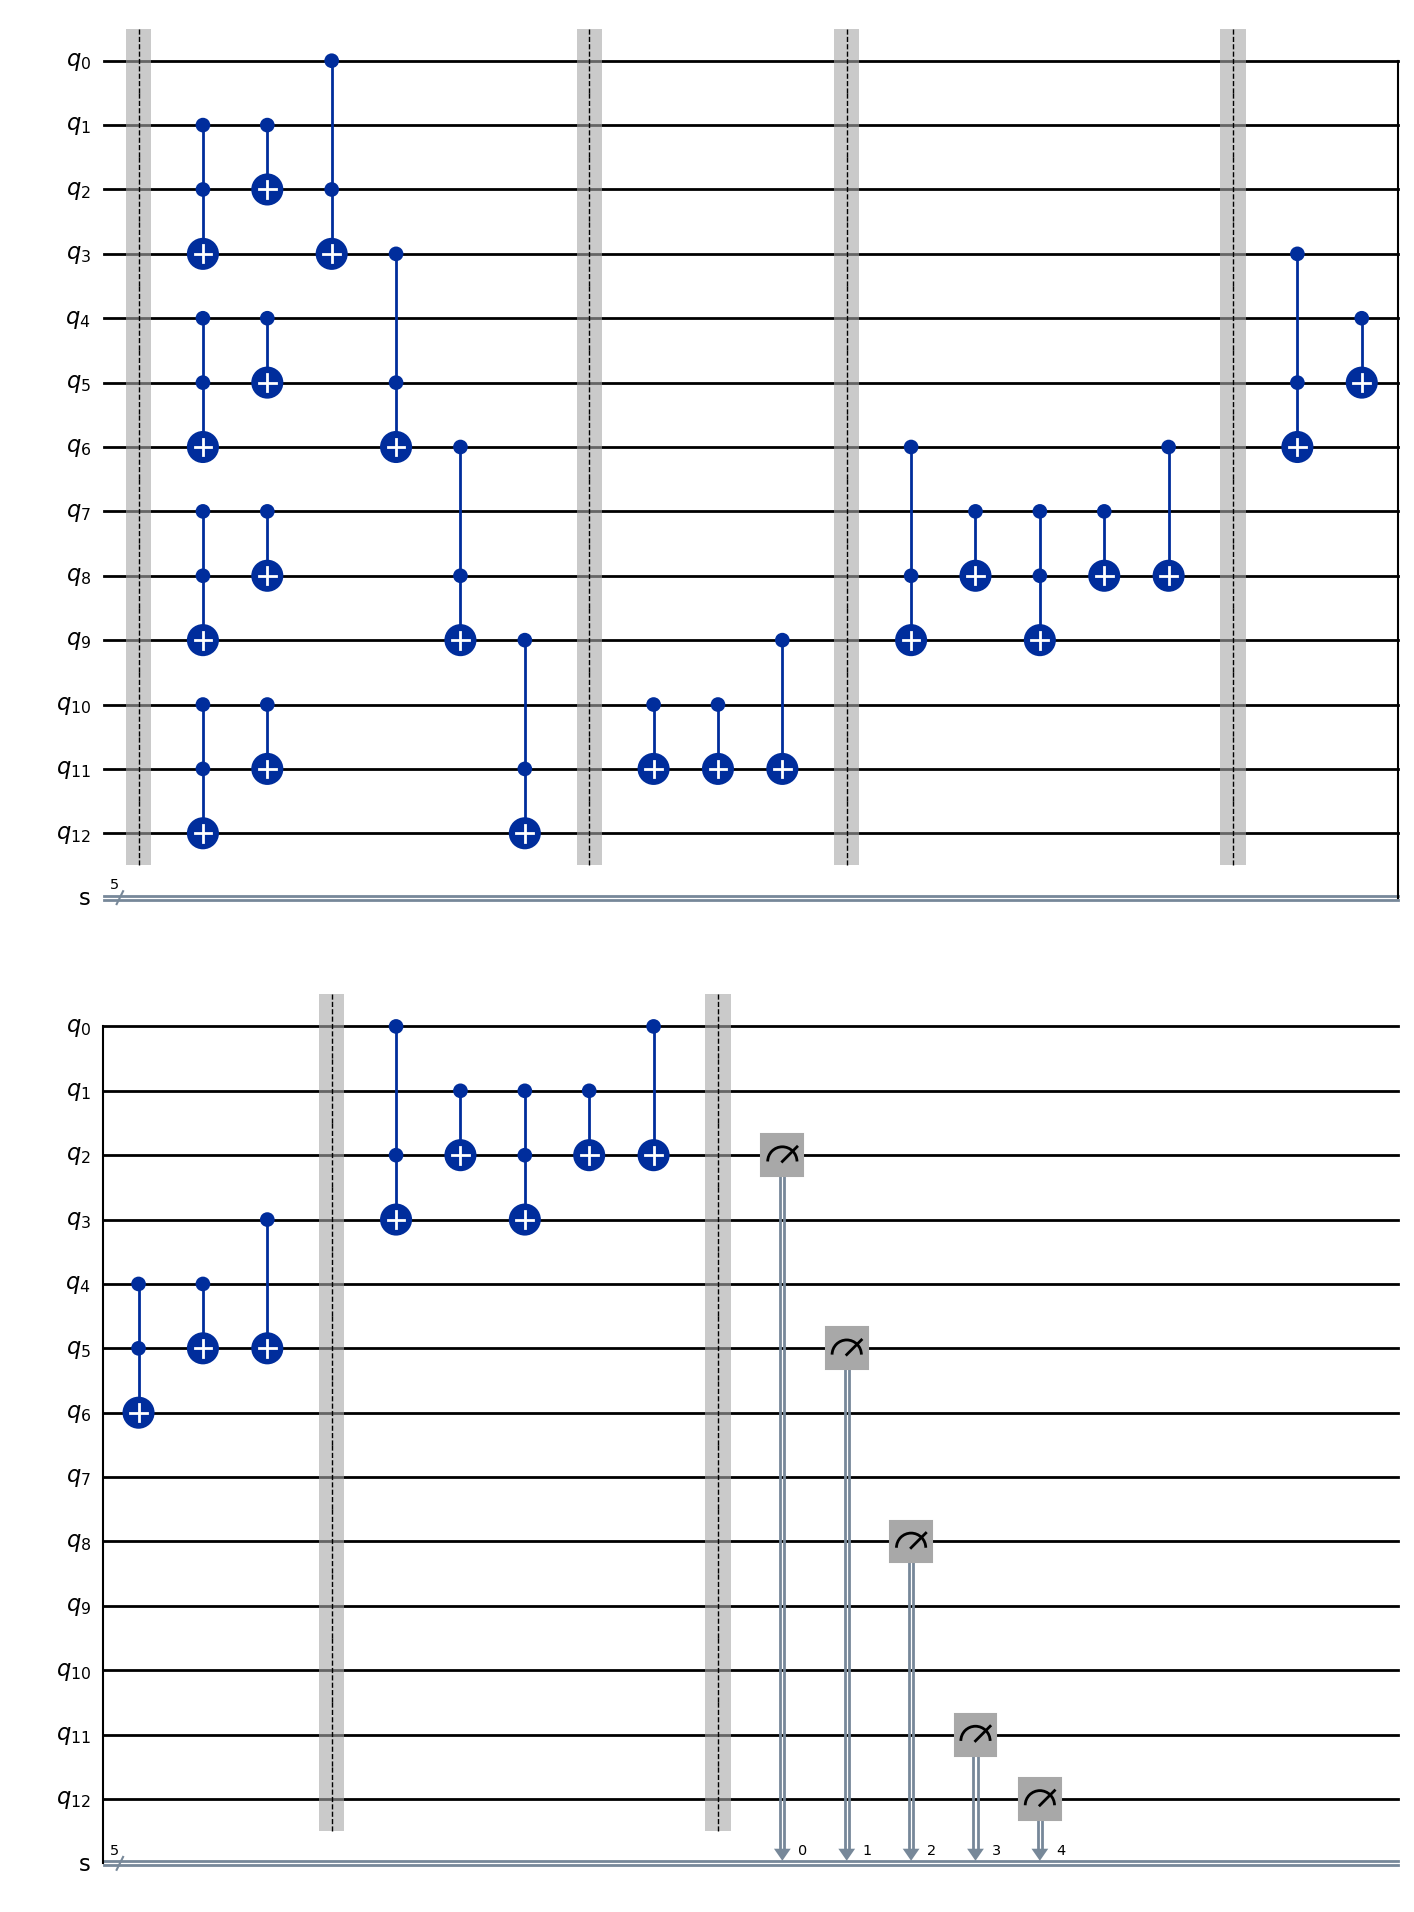

In [11]:
circuits[0].draw(output="mpl", fold=20)

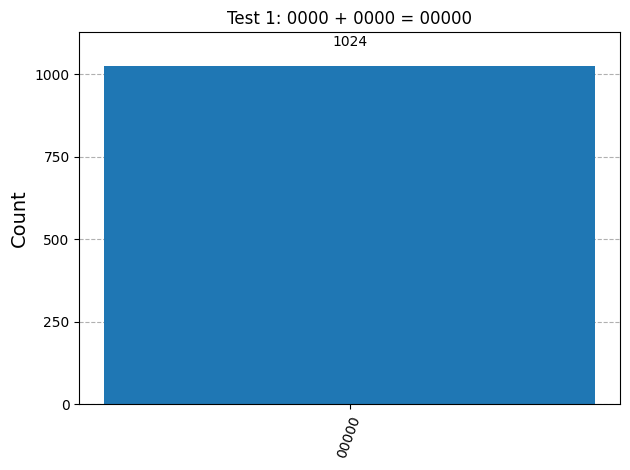

In [12]:
a, b = test_cases[0]
counts = all_counts[0]
title = f"Test 1: {a:04b} + {b:04b} = {a + b:05b}"
plot_histogram(counts, title=title)

### Observations

- The output 00000 occurred in all 1,024 shots, matching 0000 + 0000 = 00000.
- The four sum bits and the final carry-out are all zero.


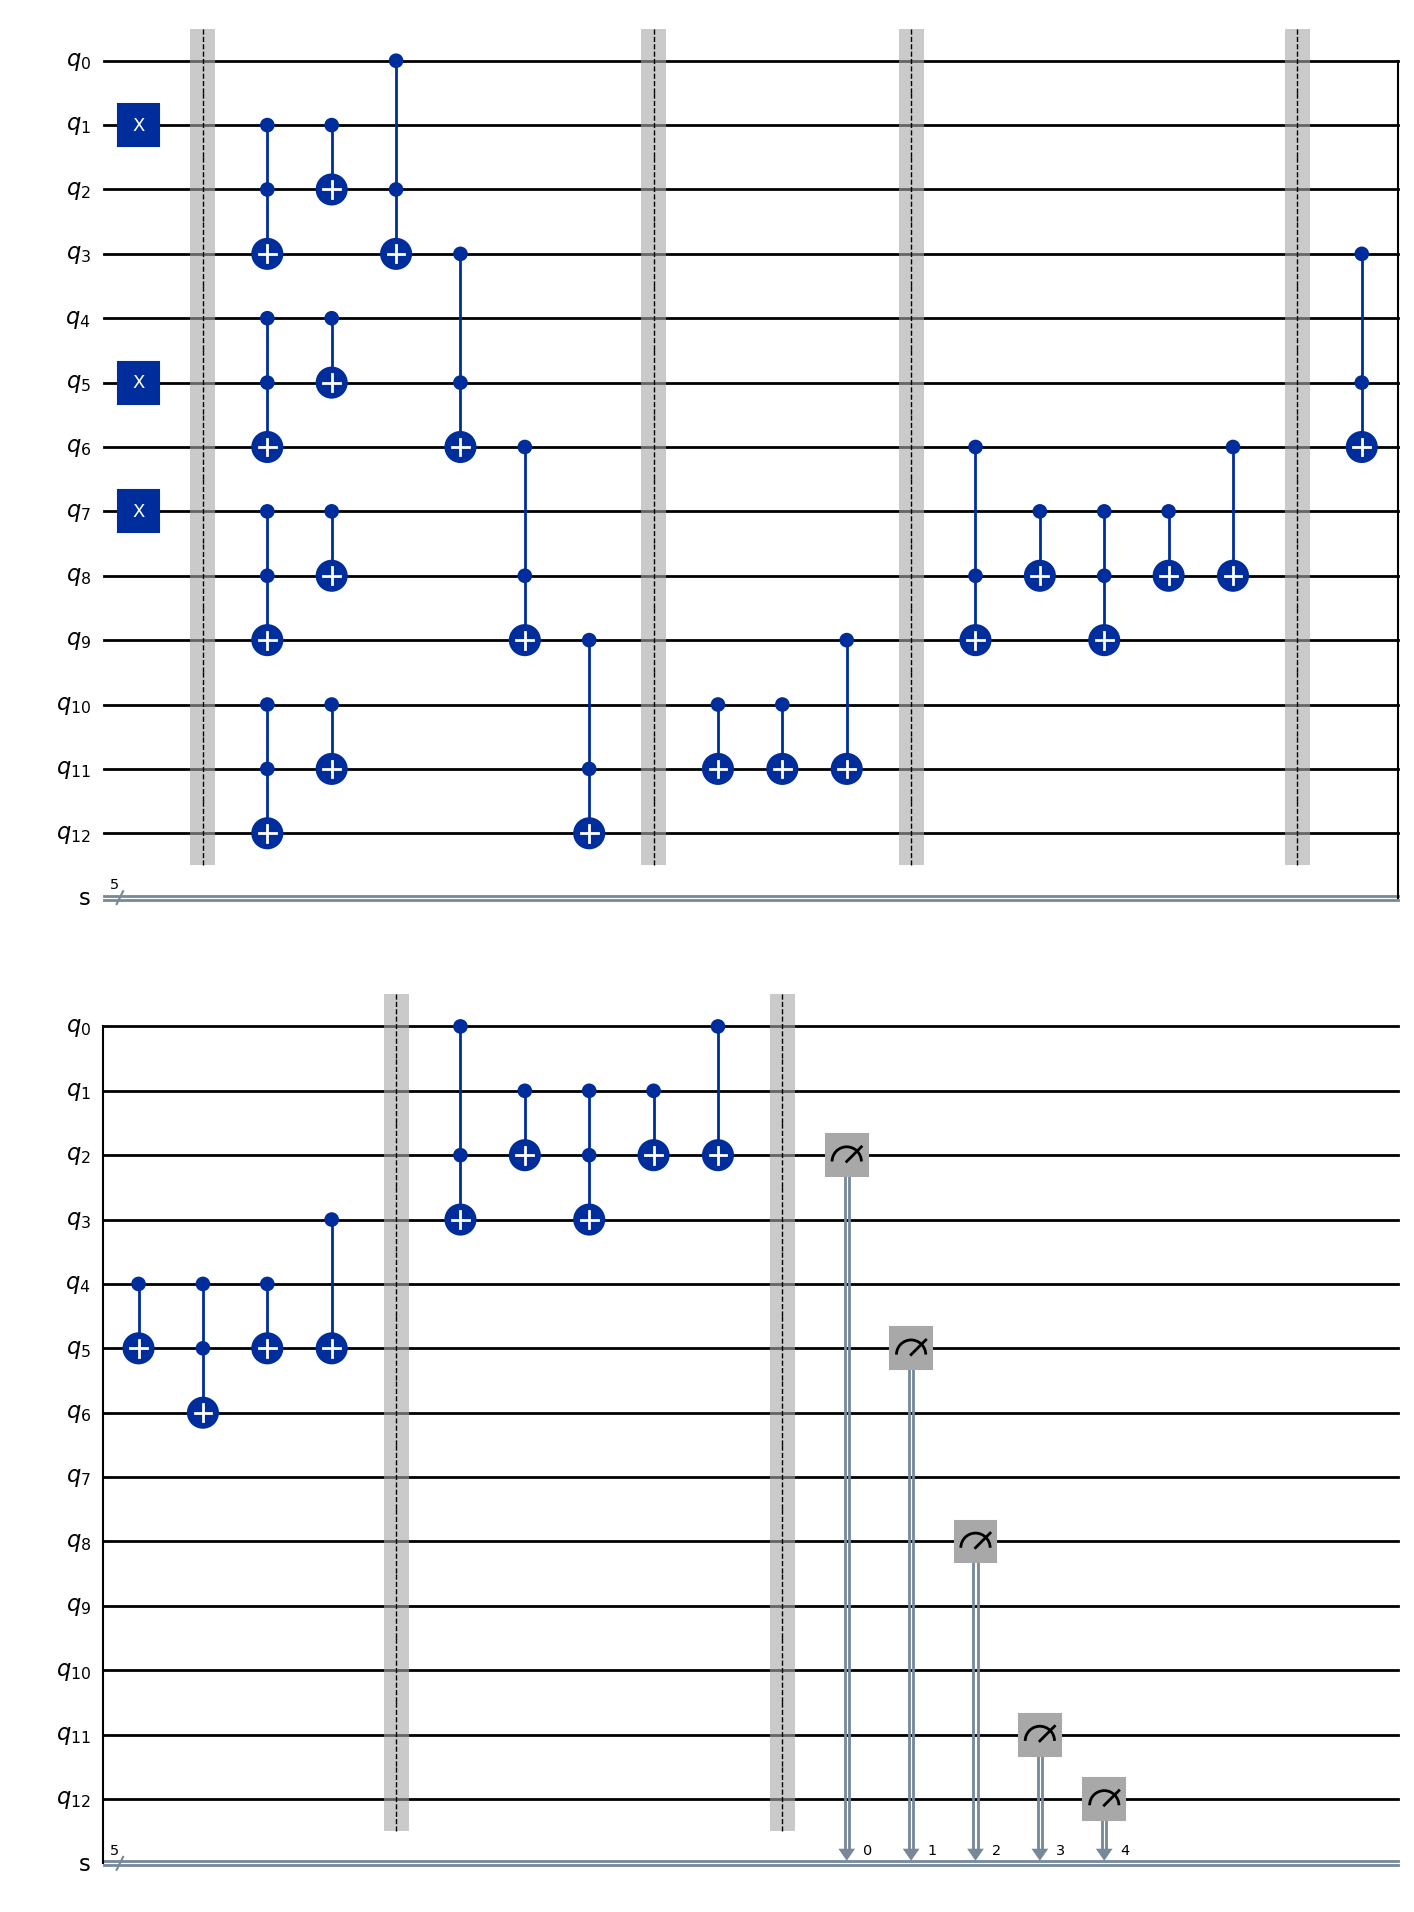

In [13]:
circuits[1].draw(output="mpl", fold=20)

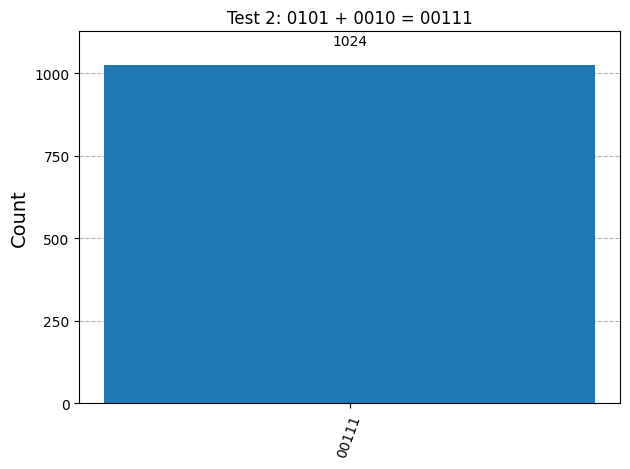

In [14]:
a, b = test_cases[1]
counts = all_counts[1]
title = f"Test 2: {a:04b} + {b:04b} = {a + b:05b}"
plot_histogram(counts, title=title)

### Observations

- The output 00111 occurred in all 1,024 shots, matching 0101 + 0010 = 00111 (5 + 2 = 7).
- No carries are generated for these operands; the final carry-out is zero.


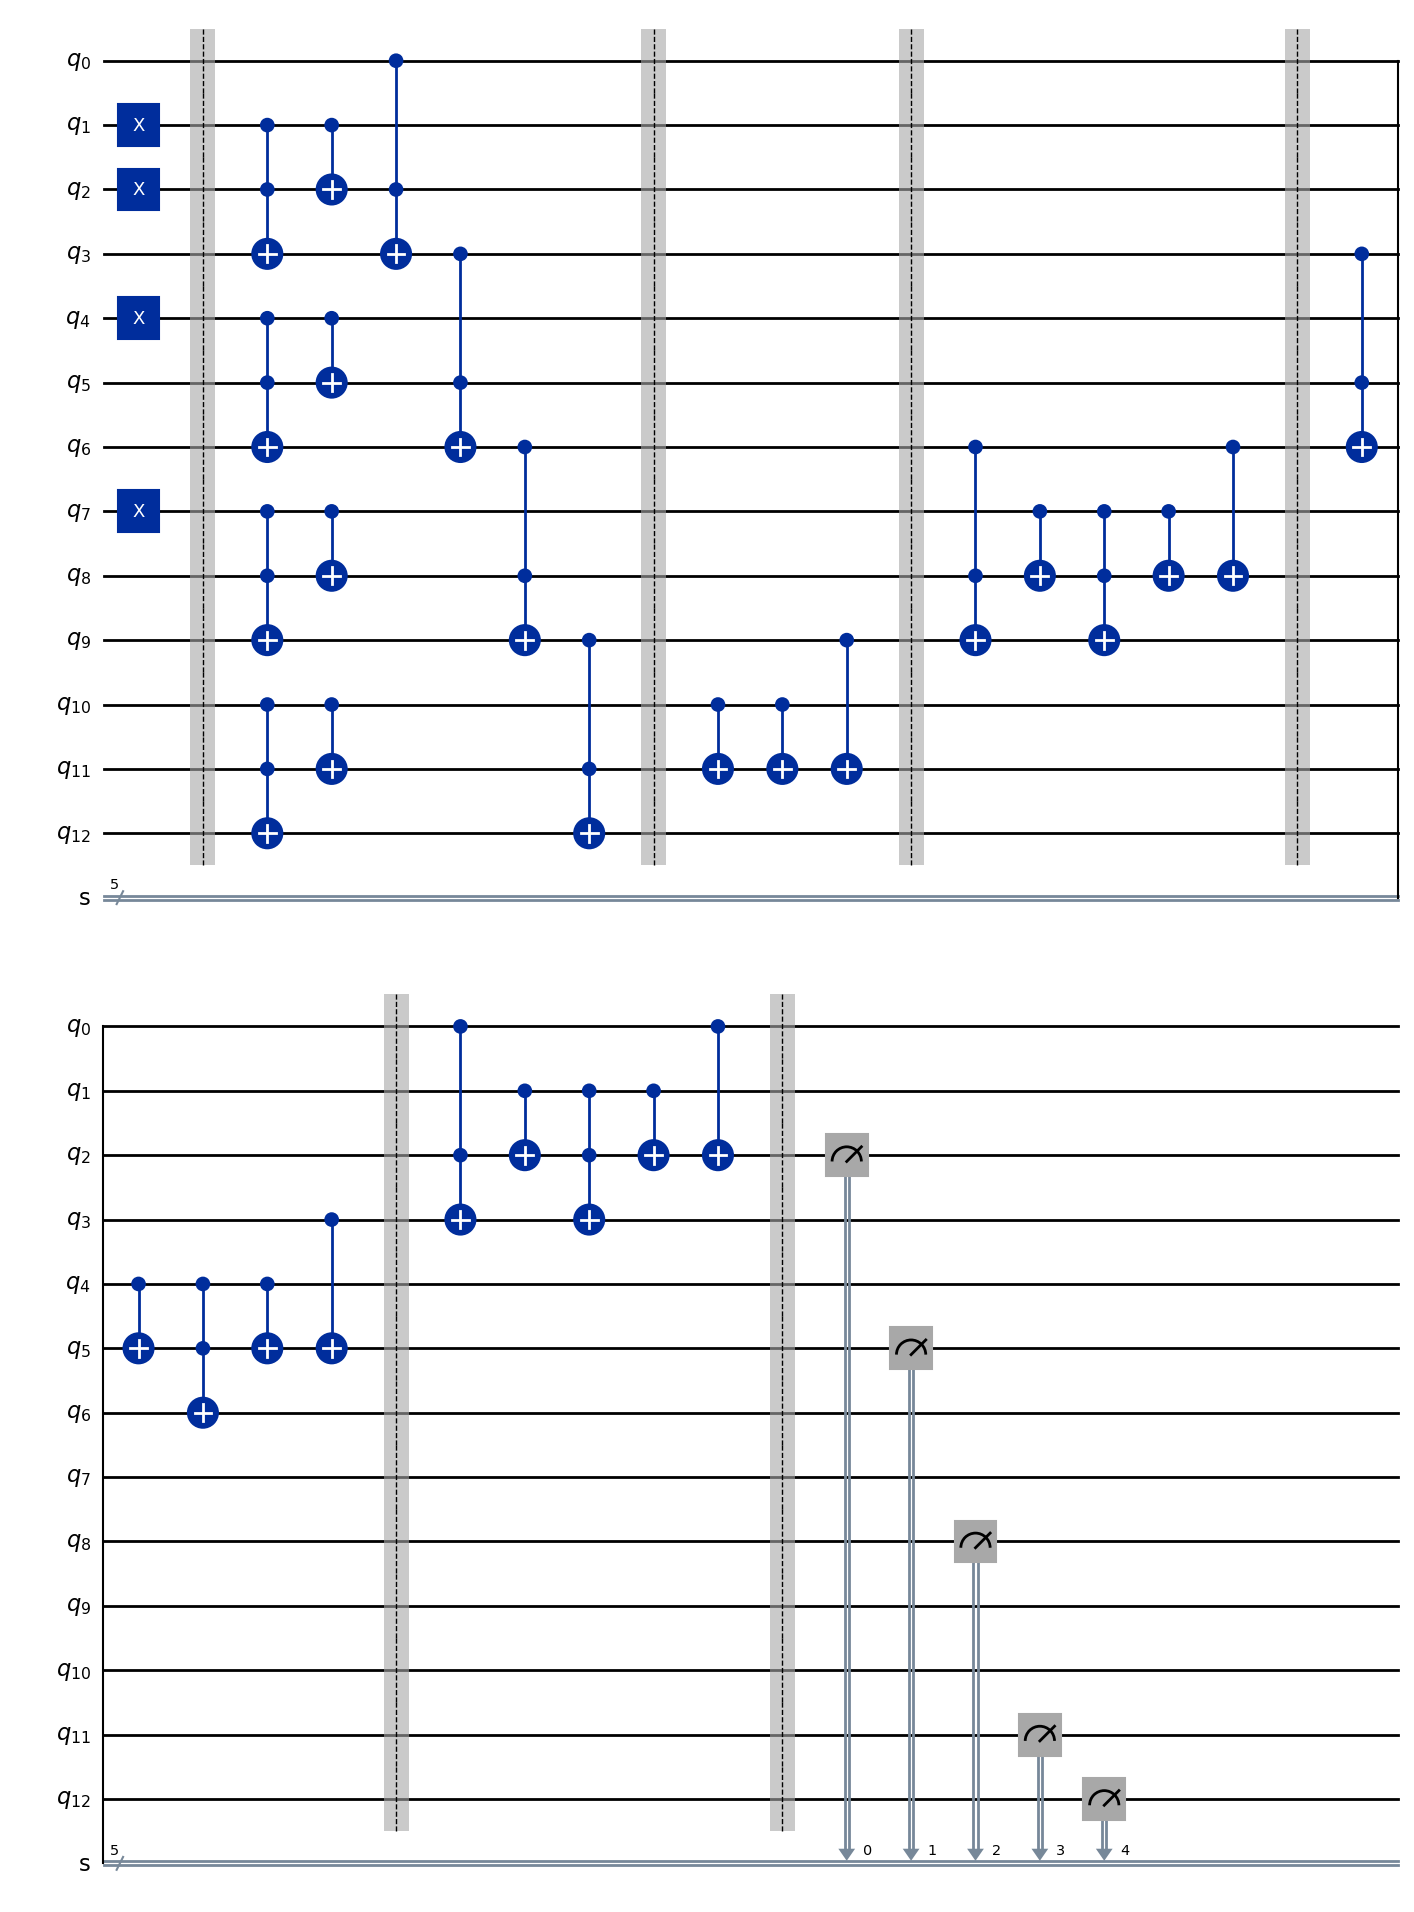

In [15]:
circuits[2].draw(output="mpl", fold=20)

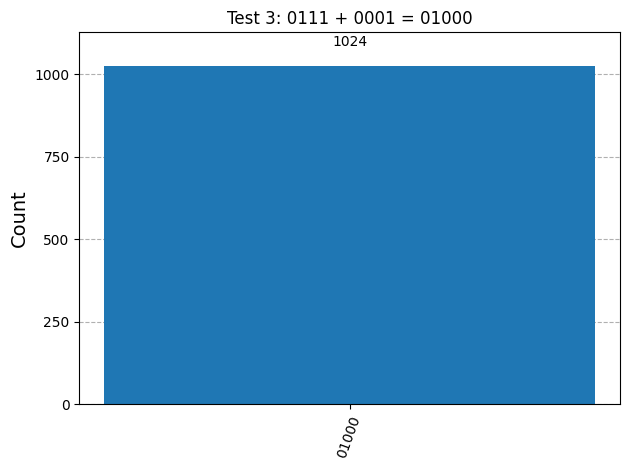

In [16]:
a, b = test_cases[2]
counts = all_counts[2]
title = f"Test 3: {a:04b} + {b:04b} = {a + b:05b}"
plot_histogram(counts, title=title)

### Observations

- The output 01000 occurred in all 1,024 shots, matching 0111 + 0001 = 01000 (7 + 1 = 8).
- The carry propagates through the lower three bit positions. The final carry-out is zero.


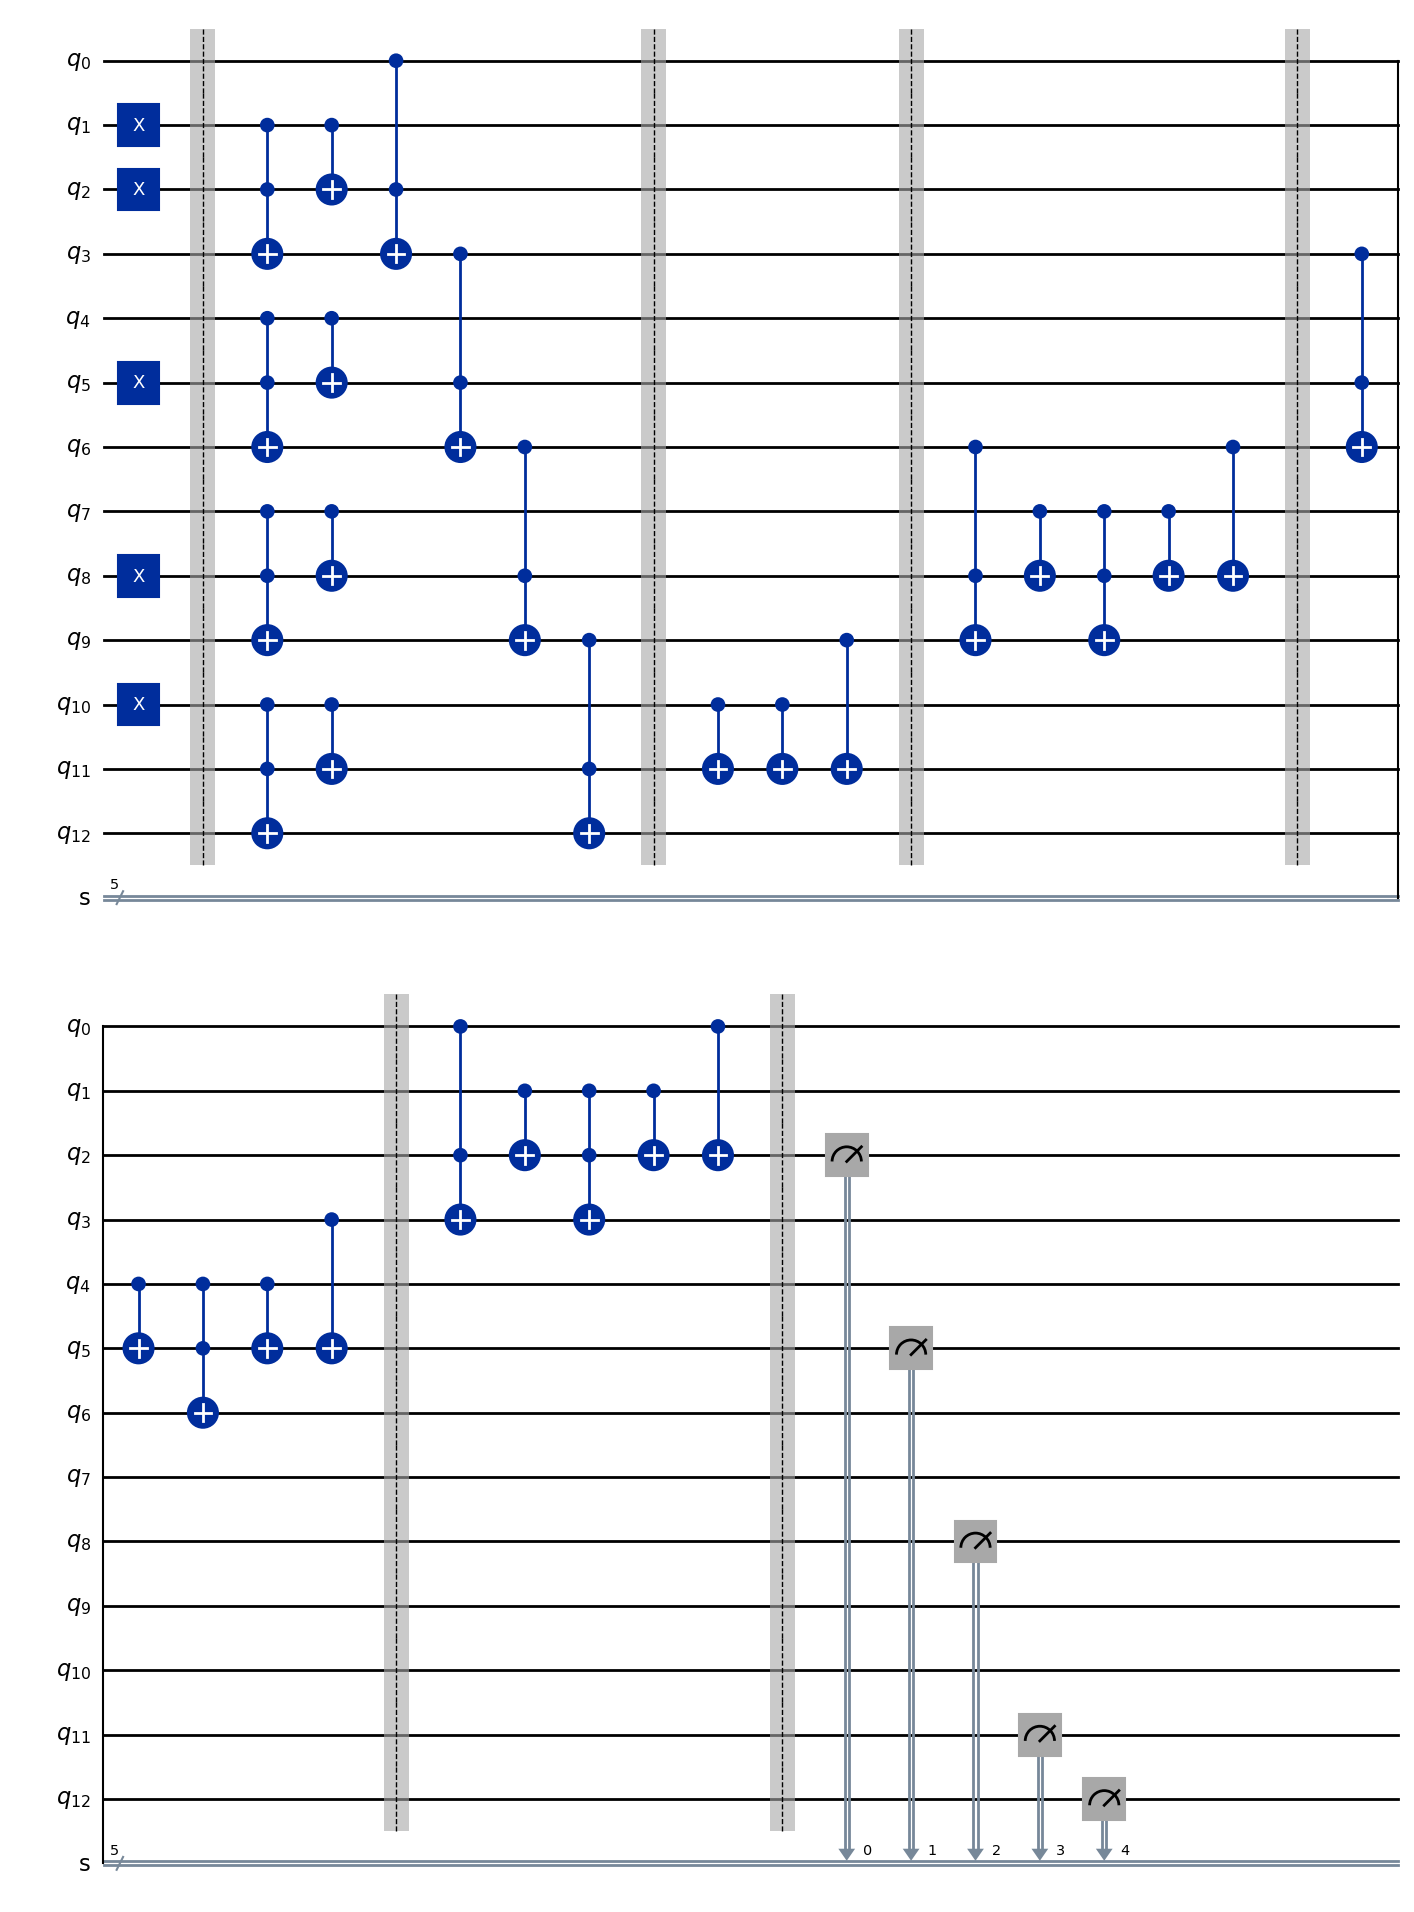

In [17]:
circuits[3].draw(output="mpl", fold=20)

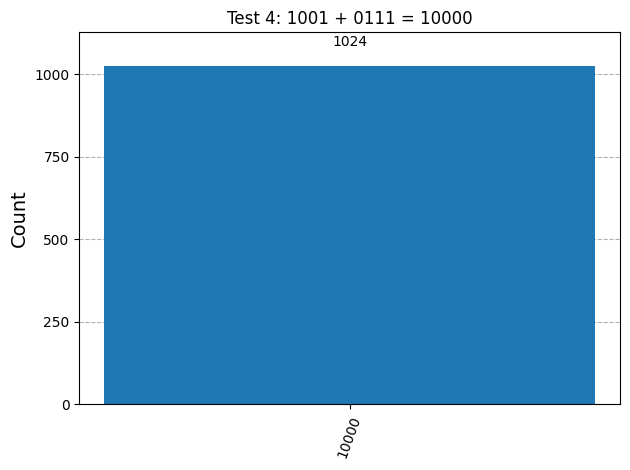

In [18]:
a, b = test_cases[3]
counts = all_counts[3]
title = f"Test 4: {a:04b} + {b:04b} = {a + b:05b}"
plot_histogram(counts, title=title)

### Observations

- The output 10000 occurred in all 1,024 shots, matching 1001 + 0111 = 10000 (9 + 7 = 16).
- The final carry-out is one and the lower four sum bits are 0000.


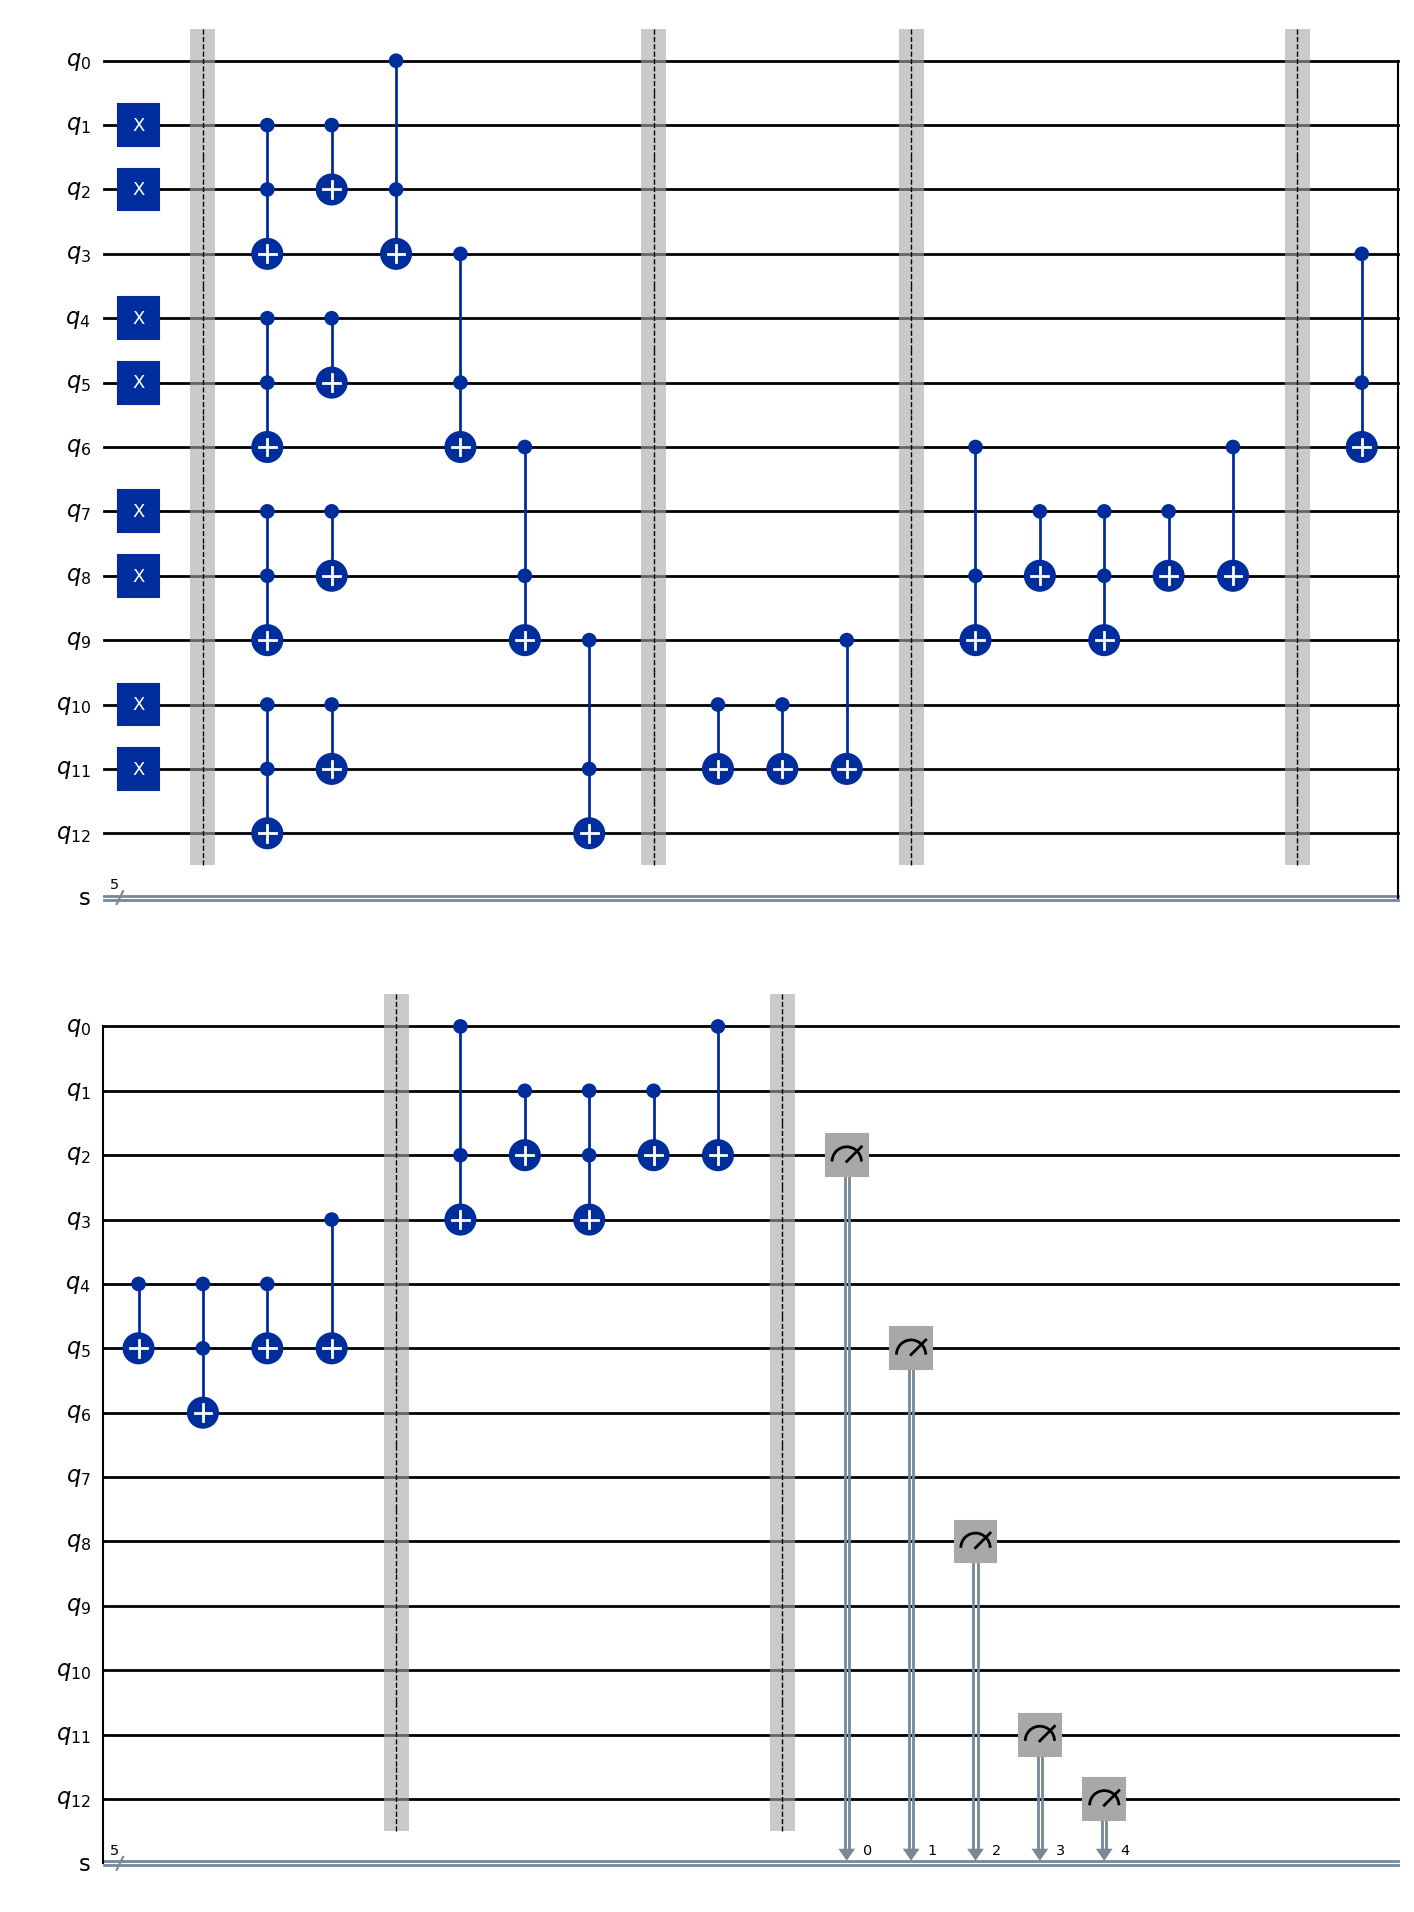

In [19]:
circuits[4].draw(output="mpl", fold=20)

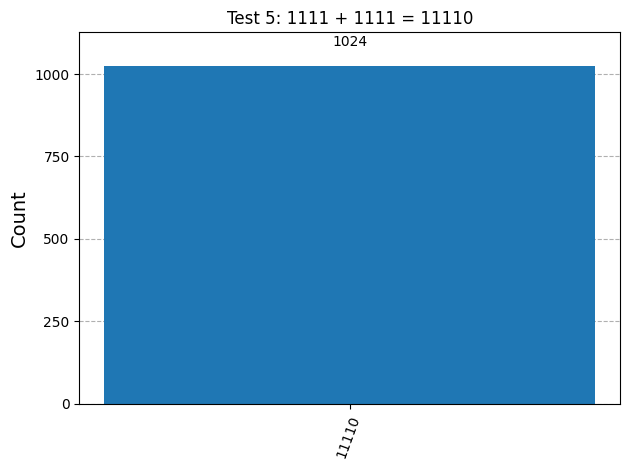

In [20]:
a, b = test_cases[4]
counts = all_counts[4]
title = f"Test 5: {a:04b} + {b:04b} = {a + b:05b}"
plot_histogram(counts, title=title)

### Observations

- The output 11110 occurred in all 1,024 shots, matching 1111 + 1111 = 11110 (15 + 15 = 30).
- For the largest four-bit operands, the final carry-out is one and the lower sum bits are 1110.
